In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F
from IPython.display import clear_output
warnings.filterwarnings("ignore")
clear_output()
from net.colei import ColEI
from net.dann import DANN
from net.simple import SimpleNet
from net.eisep import EISepNet
from net.dbp import DBPN
from net.common import init_model

In [2]:
# Environment parameters
# This setting is low to speed up testing, we recommend setting it to at least 1000
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation

rewards = {
    "abort": -0.1,
    "correct": +1.0,
    "fail": 0.0
}
sigma = 1.0 # Standard deviation of the Gaussian noise in the ring representation

In [3]:
kwargs = {'dt': dt, 'dim_ring': dim_ring}
seq_len = 100

# Make supervised dataset
tasks = get_collection('yang19')
envs = [ngym.make(task, **kwargs) for task in tasks]
schedule = RandomSchedule(len(envs))
# schedule = SequentialSchedule(len(envs))
env = ScheduleEnvs(envs, schedule=schedule, env_input=True)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env.timing)

print("\nObservation space structure:")
print(env.observation_space)

print("\nAction space structure:")
print(env.action_space)
print("Action mapping:")
print(env.action_space.name)

Trial timing (in milliseconds):
{'fixation': 500, 'stimulus': 500, 'delay': 0, 'decision': 500}

Observation space structure:
Box(-inf, inf, (25,), float32)

Action space structure:
Discrete(3)
Action mapping:
{'fixation': 0, 'choice': range(1, 3)}


In [4]:
obs, info = env.reset()

eval_monitor = Monitor(env)
print("\nEvaluating random policy performance...")
metrics = eval_monitor.evaluate_policy(num_trials=EVAL_TRIALS)
print(f"\nRandom policy metrics ({EVAL_TRIALS:,} trials):")
print(f"Mean performance: {metrics['mean_performance']:.4f}")
print(f"Mean reward: {metrics['mean_reward']:.4f}")


Evaluating random policy performance...

Random policy metrics (100 trials):
Mean performance: 0.3500
Mean reward: 0.3500


In [16]:
seq_len = 100
print(f"Using sequence length: {seq_len}")

# Make supervised dataset
batch_size = 64
print(f"Creating dataset with batch_size={batch_size}")
dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

env = dataset.env

# Extract dimensions
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n
print(act_size)
# 20 observations for one-hot encoding of the 20 environments, 1 for fixation,
# 2 for each modality (2 modalities, 4 observations total), for a total of 25 observations
print(f"Observation size: {ob_size}")
print(f"Action size: {act_size}")

# Get a batch of data
# inputs, target = dataset()
# print(f"Input batch shape: {inputs.shape}")
# print(f"Target batch shape: {target.shape}")
# print(inputs[90])

# Set device
device = 'cuda:0'
print(f"Using device: {device}")

Using sequence length: 100
Creating dataset with batch_size=64
3
Observation size: 25
Action size: 3
Using device: cuda:0


Model: eisep
Seed 1/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 2/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 3/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 4/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 5/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 6/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 7/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 8/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 9/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 10/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 11/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 12/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 13/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 14/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 15/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 16/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 17/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 18/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 19/1000
device: cuda:0
Using UnFixed EISep RNN
Seed 20/

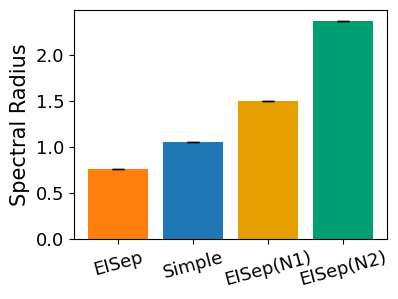

In [8]:
n_seed = 1000
epochs = 3000
hidden_size = 64
model_names = ['eisep', 'simple', 'eisep_init_ColEI', 'eisep_init_DBPN']
spectral_radii = np.zeros((len(model_names), n_seed))
legend_names = ['EISep', 'Simple', 'EISep(N1)', 'EISep(N2)']
colors = ['C1', 'C0', '#E69F00','#009E73']
for model_idx, model_name in enumerate(model_names):
    print(f"Model: {model_name}")
    for seed in range(n_seed):
        print(f"Seed {seed + 1}/{n_seed}")
        torch.manual_seed(seed+100)
        np.random.seed(seed+100)
        print('device:', device)
        net = init_model(ob_size, hidden_size, act_size, model_name).to(device)
        weight = net.get_actual_weight().detach().cpu().numpy()
        eigenvalues = np.linalg.eigvals(weight)
        spectral_radius = np.max(np.abs(eigenvalues))
        spectral_radii[model_idx, seed] = spectral_radius


./output/init/spectral_radius_comparison.pdf


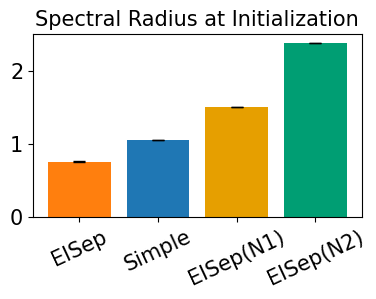

In [15]:
from net.common import savefig
fig, ax = plt.subplots(figsize=(4,3))
fontsize = 15
mean_sr = np.mean(spectral_radii, axis=1)
ste_sr = np.std(spectral_radii, axis=1) / np.sqrt(n_seed)
ax.bar(legend_names, mean_sr, yerr=ste_sr, capsize=4, color=colors)
# ax.set_ylabel('Spectral Radius', fontsize=fontsize)
ax.set_title('Spectral Radius at Initialization', fontsize=fontsize)
ax.tick_params(axis='both', which='major', labelsize=fontsize)
ax.set_xticklabels(legend_names, rotation=25)
plt.tight_layout()
savefig('./output/init/spectral_radius_comparison.pdf')